In [1]:
!pip -q install ultralytics==8.4.102 pycocotools torchmetrics pandas matplotlib pillow tqdm pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 82.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 68.7 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# ============================================================
# CELL 1 — SETUP
# ============================================================
import os, sys, json, shutil, random, time, yaml, torch
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

KAGGLE_INPUT   = Path("/content/drive/MyDrive/au-fish/dataset_v2/time_based")
PROJECT_ROOT   = Path("/content/drive/MyDrive/au-fish/dataset_v2")
DATASET_ROOT   = PROJECT_ROOT / "time_based"
RUNS_DIR       = PROJECT_ROOT / "time_based" / "runs"
RUNS_EVAL_DIR  = PROJECT_ROOT / "time_based" / "runs_eval"
PREDICTIONS_DIR = PROJECT_ROOT / "time_based" / "predictions"
EXPERIMENT_DIR = PROJECT_ROOT / "time_based" / "experiment_logs"

for d in [PROJECT_ROOT, DATASET_ROOT, RUNS_DIR, RUNS_EVAL_DIR,
          PREDICTIONS_DIR, EXPERIMENT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

if torch.cuda.is_available():
    DEVICE = "cuda"
    GPU_NAME = torch.cuda.get_device_name(0)
else:
    DEVICE = "cpu"
    GPU_NAME = "None"

print("=" * 60)
print("TIME-BASED BENCHMARK — 2 CLASSES (coral, fish)")
print("=" * 60)
print("KAGGLE_INPUT   :", KAGGLE_INPUT, "| exists:", KAGGLE_INPUT.exists())
print("PROJECT_ROOT   :", PROJECT_ROOT)
print("DEVICE         :", DEVICE)

TIME-BASED BENCHMARK — 2 CLASSES (coral, fish)
KAGGLE_INPUT   : /content/drive/MyDrive/au-fish/dataset_v2/time_based | exists: True
PROJECT_ROOT   : /content/drive/MyDrive/au-fish/dataset_v2
DEVICE         : cuda


In [4]:
# ============================================================
# CELL 2 — COPY DATASET
# ============================================================

for split in ["train", "val", "test"]:
    split_dir = DATASET_ROOT / split
    print(f"{split:5s}: images={len(list((split_dir/'images').glob('*')))}, "
          f"annotations={(split_dir/'annotations.json').exists()}")

train: images=2122, annotations=True
val  : images=406, annotations=True
test : images=564, annotations=True


In [5]:
# ============================================================
# CELL 3 — KONFIGURASI KELAS
# ============================================================
# Hanya 2 kelas: coral dan fish. Semua kelas lain di-skip.
CLASS_NAMES = ["coral", "fish"]
KEEP_CLASSES = set(CLASS_NAMES)
MIN_BOX_SIZE = 5
MIN_BOX_AREA = 25

TRAIN_DIR = DATASET_ROOT / "train"
VAL_DIR   = DATASET_ROOT / "val"
TEST_DIR  = DATASET_ROOT / "test"

print("Final classes:", CLASS_NAMES)
print("Min box size:", MIN_BOX_SIZE, "px")
print("Min box area:", MIN_BOX_AREA, "px²")

Final classes: ['coral', 'fish']
Min box size: 5 px
Min box area: 25 px²


In [6]:
# ============================================================
# CELL BARU — REPAIR DATASET + EXPLICIT IMAGE LISTS
# ============================================================
import json
import shutil
import yaml
from collections import Counter, defaultdict
from pathlib import Path

PROTOCOL = DATASET_ROOT.name

EXPECTED_COUNTS = {
    "time_based": {
        "train": {
            "images": 1061,
            "instances": 6465,
            "hidden_images": 47,
        },
        "val": {
            "images": 203,
            "instances": 913,
            "hidden_images": 8,
        },
        "test": {
            "images": 282,
            "instances": 1400,
            "hidden_images": 17,
        },
    },
    "source_based": {
        "train": {
            "images": 1083,
            "instances": 5101,
            "hidden_images": 52,
        },
        "val": {
            "images": 232,
            "instances": 1857,
            "hidden_images": 9,
        },
        "test": {
            "images": 231,
            "instances": 1820,
            "hidden_images": 11,
        },
    },
}

if PROTOCOL not in EXPECTED_COUNTS:
    raise ValueError(
        f"Protocol tidak dikenali dari DATASET_ROOT: {PROTOCOL}"
    )

SPLIT_DIRS = {
    "train": TRAIN_DIR,
    "val": VAL_DIR,
    "test": TEST_DIR,
}


def atomic_write_json(data, output_path):
    output_path = Path(output_path)
    temporary_path = output_path.with_suffix(
        output_path.suffix + ".tmp"
    )

    with open(temporary_path, "w", encoding="utf-8") as file:
        json.dump(data, file, ensure_ascii=False, indent=2)

    temporary_path.replace(output_path)


def remove_exact_duplicate_annotations(split_name, split_dir):
    """
    Menghapus annotation yang seluruh isinya identik,
    kecuali annotation ID.
    """
    split_dir = Path(split_dir)
    annotation_path = split_dir / "annotations.json"

    with open(annotation_path, "r", encoding="utf-8") as file:
        coco = json.load(file)

    image_name_by_id = {
        int(image["id"]): image["file_name"]
        for image in coco["images"]
    }

    seen = set()
    cleaned_annotations = []
    removed_annotations = []

    for annotation in coco["annotations"]:
        # ID tidak dimasukkan karena dua annotation duplicate
        # biasanya hanya berbeda annotation ID.
        comparison_record = {
            key: value
            for key, value in annotation.items()
            if key != "id"
        }

        signature = json.dumps(
            comparison_record,
            sort_keys=True,
            ensure_ascii=False,
            separators=(",", ":"),
        )

        if signature in seen:
            removed_annotations.append(annotation)
            continue

        seen.add(signature)
        cleaned_annotations.append(annotation)

    removed_files = [
        image_name_by_id.get(
            int(annotation["image_id"]),
            "UNKNOWN",
        )
        for annotation in removed_annotations
    ]

    if removed_annotations:
        backup_path = (
            split_dir
            / "annotations.before_exact_dedup.json"
        )

        if not backup_path.exists():
            shutil.copy2(annotation_path, backup_path)

        coco["annotations"] = cleaned_annotations
        atomic_write_json(coco, annotation_path)

    print(
        f"{PROTOCOL}/{split_name}: "
        f"exact duplicate annotations removed = "
        f"{len(removed_annotations)}"
    )

    if removed_files:
        print("Removed from:", removed_files)

    # Duplicate yang ditemukan hanya boleh berada di train.
    if split_name in {"val", "test"} and removed_annotations:
        raise RuntimeError(
            f"Duplicate tak terduga ditemukan di {split_name}: "
            f"{removed_files}"
        )

    if split_name == "train" and removed_annotations:
        allowed_file = (
            "GX013732_frame_000005_ts_00_02.jpg"
        )

        if set(removed_files) != {allowed_file}:
            raise RuntimeError(
                "Duplicate ditemukan pada file yang tidak "
                f"diharapkan: {removed_files}"
            )

    return len(removed_annotations)


for split_name, split_dir in SPLIT_DIRS.items():
    remove_exact_duplicate_annotations(
        split_name,
        split_dir,
    )

time_based/train: exact duplicate annotations removed = 1
Removed from: ['GX013732_frame_000005_ts_00_02.jpg']
time_based/val: exact duplicate annotations removed = 0
time_based/test: exact duplicate annotations removed = 0


In [7]:
# ============================================================
# CELL 4 — AUDIT COCO ANNOTATIONS (2 KELAS)
# ============================================================
def audit_coco_annotations(split_dir, split_name, keep_classes):
    split_dir = Path(split_dir)
    ann_path  = split_dir / "annotations.json"
    if not ann_path.exists():
        return None
    with open(ann_path, "r", encoding="utf-8") as f:
        coco = json.load(f)

    images, annotations, categories = coco["images"], coco["annotations"], coco["categories"]
    image_id_to_info = {img["id"]: img for img in images}
    cat_id_to_name   = {cat["id"]: cat["name"] for cat in categories}

    invalid, out_of_bound, tiny, kept, dropped_other = 0, 0, 0, 0, 0
    class_counter = Counter()
    all_classes_seen = Counter()

    for ann in annotations:
        img = image_id_to_info.get(ann["image_id"])
        if img is None: continue
        W, H = img["width"], img["height"]
        x, y, w, h = ann["bbox"]
        original_name = cat_id_to_name.get(ann["category_id"], "unknown")
        all_classes_seen[original_name] += 1

        if original_name not in keep_classes:
            dropped_other += 1
            continue
        if w <= 0 or h <= 0: invalid += 1; continue
        if x < 0 or y < 0 or x + w > W or y + h > H: out_of_bound += 1
        if w < MIN_BOX_SIZE or h < MIN_BOX_SIZE or (w * h) < MIN_BOX_AREA:
            tiny += 1; continue
        kept += 1
        class_counter[original_name] += 1

    print("=" * 60)
    print(split_name.upper())
    print(f"Images           : {len(images)}")
    print(f"Total annotations: {len(annotations)}")
    print(f"Dropped (other)  : {dropped_other}")
    print(f"Dropped (tiny)   : {tiny}")
    print(f"Invalid bbox     : {invalid}")
    print(f"Out-of-bound     : {out_of_bound}")
    print(f"Kept (final)     : {kept}")
    print("All classes seen :")
    for n, c in all_classes_seen.items():
        marker = "✅" if n in keep_classes else "❌ dropped"
        print(f"  {n:15s}: {c:5d}  {marker}")
    print("Kept class distribution:")
    for name in keep_classes:
        print(f"  {name:10s}: {class_counter[name]}")

    return {
        "split": split_name, "images": len(images),
        "annotations_total": len(annotations),
        "dropped_other_class": dropped_other,
        "dropped_tiny": tiny, "invalid_bbox": invalid,
        "out_of_bound_bbox": out_of_bound, "kept": kept,
        **{f"count_{n}": class_counter[n] for n in keep_classes},
    }

audit_rows = []
for split, d in [("train", TRAIN_DIR), ("val", VAL_DIR), ("test", TEST_DIR)]:
    row = audit_coco_annotations(d, split, KEEP_CLASSES)
    if row: audit_rows.append(row)

audit_df = pd.DataFrame(audit_rows)
display(audit_df)
audit_df.to_csv(EXPERIMENT_DIR / "time_based_audit_summary.csv", index=False)

TRAIN
Images           : 1061
Total annotations: 6563
Dropped (other)  : 41
Dropped (tiny)   : 1
Invalid bbox     : 0
Out-of-bound     : 220
Kept (final)     : 6521
All classes seen :
  eel            :     1  ❌ dropped
  sea_eel        :    16  ❌ dropped
  fish           :  4734  ✅
  coral          :  1788  ✅
  turtle         :    14  ❌ dropped
  sea_snake      :     8  ❌ dropped
  fish'          :     1  ❌ dropped
  fisch          :     1  ❌ dropped
Kept class distribution:
  fish      : 4733
  coral     : 1788
VAL
Images           : 203
Total annotations: 931
Dropped (other)  : 10
Dropped (tiny)   : 0
Invalid bbox     : 0
Out-of-bound     : 31
Kept (final)     : 921
All classes seen :
  sea_eel        :     3  ❌ dropped
  fish           :   641  ✅
  coral          :   280  ✅
  turtle         :     3  ❌ dropped
  sea_snake      :     1  ❌ dropped
  colar          :     1  ❌ dropped
  fahrinfffi     :     1  ❌ dropped
  jana           :     1  ❌ dropped
Kept class distribution:
  fish

,split,images,annotations_total,dropped_other_class,dropped_tiny,invalid_bbox,out_of_bound_bbox,kept,count_fish,count_coral
0,train,1061,6563,41,1,0,220,6521,4733,1788
1,val,203,931,10,0,0,31,921,641,280
2,test,282,1427,11,0,0,48,1416,1051,365


In [ ]:
# ============================================================
# CELL 5 — KONVERSI COCO → YOLO (2 KELAS + FILTER)
# ============================================================
def convert_coco_to_yolo(split_dir, split_name, class_names, keep_classes,
                         min_box_size=MIN_BOX_SIZE, min_box_area=MIN_BOX_AREA):
    split_dir  = Path(split_dir)
    ann_path   = split_dir / "annotations.json"
    labels_dir = split_dir / "labels"
    labels_dir.mkdir(parents=True, exist_ok=True)

    with open(ann_path, "r", encoding="utf-8") as f:
        coco = json.load(f)

    images, annotations, categories = coco["images"], coco["annotations"], coco["categories"]
    cat_id_to_name        = {cat["id"]: cat["name"] for cat in categories}
    class_name_to_yolo_id = {name: idx for idx, name in enumerate(class_names)}

    image_id_to_anns = defaultdict(list)
    for ann in annotations:
        image_id_to_anns[ann["image_id"]].append(ann)

    total_boxes, skipped_tiny, skipped_other, skipped_invalid, clamped = 0, 0, 0, 0, 0
    class_counter = Counter()

    for img in images:
        img_id, filename = img["id"], img["file_name"]
        W, H = img["width"], img["height"]
        label_path = labels_dir / (Path(filename).stem + ".txt")
        lines = []

        for ann in image_id_to_anns.get(img_id, []):
            if "bbox" not in ann: continue
            x, y, w, h = ann["bbox"]
            original_name = cat_id_to_name[ann["category_id"]]

            if original_name not in keep_classes:
                skipped_other += 1; continue

            if w <= 0 or h <= 0:
                skipped_invalid += 1; continue

            # Clamp ke image boundaries
            x1_raw, y1_raw = float(x), float(y)
            x2_raw, y2_raw = float(x + w), float(y + h)
            x1 = max(0.0, x1_raw); y1 = max(0.0, y1_raw)
            x2 = min(float(W), x2_raw); y2 = min(float(H), y2_raw)
            if (x1 != x1_raw or y1 != y1_raw or x2 != x2_raw or y2 != y2_raw):
                clamped += 1

            bw, bh = x2 - x1, y2 - y1

            # Filter box terlalu kecil
            if bw < min_box_size or bh < min_box_size or (bw * bh) < min_box_area:
                skipped_tiny += 1; continue

            cls_id  = class_name_to_yolo_id[original_name]
            xc      = (x1 + bw / 2) / W
            yc      = (y1 + bh / 2) / H
            bw_norm = bw / W
            bh_norm = bh / H

            lines.append(f"{cls_id} {xc:.6f} {yc:.6f} {bw_norm:.6f} {bh_norm:.6f}")
            total_boxes += 1
            class_counter[original_name] += 1

        with open(label_path, "w", encoding="utf-8") as f:
            f.write("\n".join(lines))

    print("=" * 60)
    print(split_name.upper())
    print(f"Images        : {len(images)}")
    print(f"Label files   : {len(list(labels_dir.glob('*.txt')))}")
    print(f"Boxes kept    : {total_boxes}")
    print(f"Skipped other : {skipped_other}")
    print(f"Skipped tiny  : {skipped_tiny}")
    print(f"Skipped inval : {skipped_invalid}")
    print(f"Clamped       : {clamped}")
    for name in class_names:
        print(f"  {name:10s}: {class_counter[name]}")

    return class_counter

print("Converting COCO → YOLO (2 classes: coral, fish)...")
for split, d in [("train", TRAIN_DIR), ("val", VAL_DIR), ("test", TEST_DIR)]:
    convert_coco_to_yolo(d, split, CLASS_NAMES, KEEP_CLASSES)

Converting COCO → YOLO (2 classes: coral, fish)...
TRAIN
Images        : 1061
Label files   : 1061
Boxes kept    : 6466
Skipped other : 41
Skipped tiny  : 57
Skipped inval : 0
Clamped       : 220
  coral     : 1788
  fish      : 4678
VAL
Images        : 203
Label files   : 203
Boxes kept    : 913
Skipped other : 10
Skipped tiny  : 8
Skipped inval : 0
Clamped       : 31
  coral     : 280
  fish      : 633
TEST
Images        : 282
Label files   : 282
Boxes kept    : 1400
Skipped other : 11
Skipped tiny  : 16
Skipped inval : 0
Clamped       : 48
  coral     : 365
  fish      : 1035


In [8]:
# ============================================================
# CELL 5 — REBUILD COCO → YOLO, DEDUPLICATED
# ============================================================
def rebuild_coco_to_yolo(
    split_dir,
    split_name,
    class_names,
    keep_classes,
    min_box_size=MIN_BOX_SIZE,
    min_box_area=MIN_BOX_AREA,
):
    split_dir = Path(split_dir)
    annotation_path = split_dir / "annotations.json"
    labels_dir = split_dir / "labels"

    # Hapus seluruh label lama agar tidak ada stale file.
    if labels_dir.exists():
        shutil.rmtree(labels_dir)

    labels_dir.mkdir(parents=True, exist_ok=True)

    with open(
        annotation_path,
        "r",
        encoding="utf-8",
    ) as file:
        coco = json.load(file)

    images = coco["images"]
    annotations = coco["annotations"]
    categories = coco["categories"]

    category_id_to_name = {
        int(category["id"]): category["name"]
        for category in categories
    }

    class_name_to_id = {
        name: index
        for index, name in enumerate(class_names)
    }

    annotations_by_image = defaultdict(list)

    for annotation in annotations:
        annotations_by_image[
            int(annotation["image_id"])
        ].append(annotation)

    total_instances = 0
    duplicate_yolo_rows_removed = 0
    class_counter = Counter()

    for image_info in images:
        image_id = int(image_info["id"])
        filename = image_info["file_name"]
        image_width = float(image_info["width"])
        image_height = float(image_info["height"])

        # Preserves leading dot:
        # .trashed-example.jpg -> .trashed-example.txt
        label_name = (
            Path(filename)
            .with_suffix(".txt")
            .name
        )
        label_path = labels_dir / label_name

        output_rows = []
        seen_rows = set()

        for annotation in annotations_by_image.get(
            image_id,
            [],
        ):
            category_name = category_id_to_name.get(
                int(annotation["category_id"])
            )

            if category_name not in keep_classes:
                continue

            bbox = annotation.get("bbox")

            if (
                not isinstance(bbox, (list, tuple))
                or len(bbox) != 4
            ):
                continue

            x, y, width, height = map(float, bbox)

            if (
                width <= 0
                or height <= 0
                or image_width <= 0
                or image_height <= 0
            ):
                continue

            x1 = max(0.0, x)
            y1 = max(0.0, y)
            x2 = min(image_width, x + width)
            y2 = min(image_height, y + height)

            clipped_width = x2 - x1
            clipped_height = y2 - y1

            if (
                clipped_width < min_box_size
                or clipped_height < min_box_size
                or clipped_width * clipped_height
                < min_box_area
            ):
                continue

            class_id = class_name_to_id[category_name]

            x_center = (
                x1 + clipped_width / 2.0
            ) / image_width
            y_center = (
                y1 + clipped_height / 2.0
            ) / image_height
            width_normalized = (
                clipped_width / image_width
            )
            height_normalized = (
                clipped_height / image_height
            )

            row_values = (
                int(class_id),
                round(x_center, 8),
                round(y_center, 8),
                round(width_normalized, 8),
                round(height_normalized, 8),
            )

            if row_values in seen_rows:
                duplicate_yolo_rows_removed += 1
                continue

            seen_rows.add(row_values)
            output_rows.append(
                f"{class_id} "
                f"{x_center:.6f} "
                f"{y_center:.6f} "
                f"{width_normalized:.6f} "
                f"{height_normalized:.6f}"
            )

            class_counter[category_name] += 1
            total_instances += 1

        # File kosong tetap dibuat untuk negative/background image.
        with open(
            label_path,
            "w",
            encoding="utf-8",
        ) as file:
            file.write("\n".join(output_rows))

    expected = EXPECTED_COUNTS[
        PROTOCOL
    ][split_name]

    if len(images) != expected["images"]:
        raise RuntimeError(
            f"{split_name}: expected "
            f"{expected['images']} images, "
            f"found {len(images)}"
        )

    if total_instances != expected["instances"]:
        raise RuntimeError(
            f"{split_name}: expected "
            f"{expected['instances']} instances, "
            f"generated {total_instances}"
        )

    print("=" * 70)
    print(f"{PROTOCOL}/{split_name}")
    print("Images                  :", len(images))
    print("YOLO instances          :", total_instances)
    print("Coral                   :", class_counter["coral"])
    print("Fish                    :", class_counter["fish"])
    print(
        "Extra YOLO duplicates removed:",
        duplicate_yolo_rows_removed,
    )

    return {
        "split": split_name,
        "images": len(images),
        "instances": total_instances,
        "coral": class_counter["coral"],
        "fish": class_counter["fish"],
    }


label_build_rows = []

for split_name, split_dir in SPLIT_DIRS.items():
    label_build_rows.append(
        rebuild_coco_to_yolo(
            split_dir=split_dir,
            split_name=split_name,
            class_names=CLASS_NAMES,
            keep_classes=KEEP_CLASSES,
        )
    )

label_build_df = pd.DataFrame(label_build_rows)
display(label_build_df)

time_based/train
Images                  : 1061
YOLO instances          : 6465
Coral                   : 1788
Fish                    : 4677
Extra YOLO duplicates removed: 0
time_based/val
Images                  : 203
YOLO instances          : 913
Coral                   : 280
Fish                    : 633
Extra YOLO duplicates removed: 0
time_based/test
Images                  : 282
YOLO instances          : 1400
Coral                   : 365
Fish                    : 1035
Extra YOLO duplicates removed: 0


,split,images,instances,coral,fish
0,train,1061,6465,1788,4677
1,val,203,913,280,633
2,test,282,1400,365,1035


In [9]:
# ============================================================
# CELL 6 — VALIDASI IMAGE-LABEL PAIR
# ============================================================
def validate_image_label_pair(split_dir, split_name):
    split_dir  = Path(split_dir)
    images_dir = split_dir / "images"
    labels_dir = split_dir / "labels"

    image_files = []
    for ext in ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]:
        image_files.extend(images_dir.glob(ext))

    missing, empty, non_empty = [], [], []
    for img_path in image_files:
        label_path = labels_dir / f"{img_path.stem}.txt"
        if not label_path.exists():
            missing.append(img_path.name)
        else:
            content = label_path.read_text(encoding="utf-8").strip()
            if content == "": empty.append(label_path.name)
            else: non_empty.append(label_path.name)

    print("=" * 60)
    print(split_name.upper())
    print(f"Images       : {len(image_files)}")
    print(f"Missing lbl  : {len(missing)}")
    print(f"Empty lbl    : {len(empty)}")
    print(f"Non-empty lbl: {len(non_empty)}")
    return {"split": split_name, "images": len(image_files),
            "missing_labels": len(missing), "empty_labels": len(empty),
            "non_empty_labels": len(non_empty)}

pair_rows = []
for split, d in [("train", TRAIN_DIR), ("val", VAL_DIR), ("test", TEST_DIR)]:
    pair_rows.append(validate_image_label_pair(d, split))
display(pd.DataFrame(pair_rows))

TRAIN
Images       : 1061
Missing lbl  : 0
Empty lbl    : 23
Non-empty lbl: 1038
VAL
Images       : 203
Missing lbl  : 0
Empty lbl    : 4
Non-empty lbl: 199
TEST
Images       : 282
Missing lbl  : 0
Empty lbl    : 10
Non-empty lbl: 272


,split,images,missing_labels,empty_labels,non_empty_labels
0,train,1061,0,23,1038
1,val,203,0,4,199
2,test,282,0,10,272


In [ ]:
# ============================================================
# CELL 7 — BUAT YAML
# ============================================================
yaml_path = DATASET_ROOT / "aufish_time_based.yaml"
data_yaml = {
    "path": str(DATASET_ROOT),
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "names": {i: name for i, name in enumerate(CLASS_NAMES)},
}
with open(yaml_path, "w", encoding="utf-8") as f:
    yaml.dump(data_yaml, f, sort_keys=False)
print("Saved:", yaml_path)
print(yaml.dump(data_yaml, sort_keys=False))

Saved: /content/drive/MyDrive/au-fish/dataset_v2/time_based/aufish_time_based.yaml
path: /content/drive/MyDrive/au-fish/dataset_v2/time_based
train: train/images
val: val/images
test: test/images
names:
  0: coral
  1: fish



In [10]:
# ============================================================
# CELL 7 — EXPLICIT IMAGE LISTS + YAML
# ============================================================
def create_explicit_image_list(
    split_name,
    split_dir,
):
    split_dir = Path(split_dir)
    annotation_path = split_dir / "annotations.json"
    images_dir = split_dir / "images"

    with open(
        annotation_path,
        "r",
        encoding="utf-8",
    ) as file:
        coco = json.load(file)

    image_paths = []
    hidden_paths = []

    for image_info in coco["images"]:
        relative_path = Path(
            image_info["file_name"]
        )

        image_path = (
            images_dir / relative_path
        ).resolve()

        if not image_path.exists():
            raise FileNotFoundError(
                f"Image tidak ditemukan: {image_path}"
            )

        image_paths.append(str(image_path))

        if image_path.name.startswith("."):
            hidden_paths.append(str(image_path))

    if len(image_paths) != len(set(image_paths)):
        raise RuntimeError(
            f"Duplicate path ditemukan di {split_name}"
        )

    expected = EXPECTED_COUNTS[
        PROTOCOL
    ][split_name]

    if len(image_paths) != expected["images"]:
        raise RuntimeError(
            f"{split_name}: expected "
            f"{expected['images']} image paths, "
            f"found {len(image_paths)}"
        )

    if len(hidden_paths) != expected["hidden_images"]:
        raise RuntimeError(
            f"{split_name}: expected "
            f"{expected['hidden_images']} hidden images, "
            f"found {len(hidden_paths)}"
        )

    list_path = (
        DATASET_ROOT
        / f"{split_name}_images.txt"
    )

    list_path.write_text(
        "\n".join(image_paths) + "\n",
        encoding="utf-8",
    )

    print(
        f"{split_name:5s}: "
        f"images={len(image_paths)}, "
        f"hidden={len(hidden_paths)}, "
        f"list={list_path}"
    )

    return list_path


image_list_paths = {}

for split_name, split_dir in SPLIT_DIRS.items():
    image_list_paths[split_name] = (
        create_explicit_image_list(
            split_name,
            split_dir,
        )
    )


# Hapus semua cache Ultralytics lama.
removed_caches = []

for cache_path in DATASET_ROOT.rglob("*.cache"):
    removed_caches.append(str(cache_path))
    cache_path.unlink()

print(
    "Caches removed:",
    len(removed_caches),
)

for cache_path in removed_caches:
    print(" -", cache_path)


yaml_path = (
    DATASET_ROOT
    / f"aufish_{PROTOCOL}_fullset.yaml"
)

data_yaml = {
    "path": str(DATASET_ROOT),
    "train": str(image_list_paths["train"]),
    "val": str(image_list_paths["val"]),
    "test": str(image_list_paths["test"]),
    "names": {
        0: "coral",
        1: "fish",
    },
}

with open(
    yaml_path,
    "w",
    encoding="utf-8",
) as file:
    yaml.safe_dump(
        data_yaml,
        file,
        sort_keys=False,
    )

print("\nSaved YAML:", yaml_path)
print(yaml.safe_dump(data_yaml, sort_keys=False))

train: images=1061, hidden=47, list=/content/drive/MyDrive/au-fish/dataset_v2/time_based/train_images.txt
val  : images=203, hidden=8, list=/content/drive/MyDrive/au-fish/dataset_v2/time_based/val_images.txt
test : images=282, hidden=17, list=/content/drive/MyDrive/au-fish/dataset_v2/time_based/test_images.txt
Caches removed: 3
 - /content/drive/MyDrive/au-fish/dataset_v2/time_based/train/labels.cache
 - /content/drive/MyDrive/au-fish/dataset_v2/time_based/val/labels.cache
 - /content/drive/MyDrive/au-fish/dataset_v2/time_based/test/labels.cache

Saved YAML: /content/drive/MyDrive/au-fish/dataset_v2/time_based/aufish_time_based_fullset.yaml
path: /content/drive/MyDrive/au-fish/dataset_v2/time_based
train: /content/drive/MyDrive/au-fish/dataset_v2/time_based/train_images.txt
val: /content/drive/MyDrive/au-fish/dataset_v2/time_based/val_images.txt
test: /content/drive/MyDrive/au-fish/dataset_v2/time_based/test_images.txt
names:
  0: coral
  1: fish



In [11]:
# ============================================================
# CELL 8 — HELPER: MASTER LOG
# ============================================================
MASTER_LOG = EXPERIMENT_DIR / "all_evaluation_results_merged.csv"

def append_to_master_log(result_row, master_log_path=MASTER_LOG):
    master_log_path = Path(master_log_path)
    if master_log_path.exists():
        old_df = pd.read_csv(master_log_path)
        new_df = pd.concat([old_df, pd.DataFrame([result_row])], ignore_index=True)
    else:
        new_df = pd.DataFrame([result_row])
    if "eval_name" in new_df.columns:
        new_df = new_df.drop_duplicates(subset=["eval_name"], keep="last")
    new_df.to_csv(master_log_path, index=False)
    return new_df

In [12]:
# ============================================================
# CELL BARU — ULTRALYTICS LOADER PREFLIGHT
# ============================================================
from ultralytics.data.dataset import YOLODataset

preflight_rows = []

for split_name in ["train", "val", "test"]:
    list_path = image_list_paths[split_name]

    dataset = YOLODataset(
        img_path=str(list_path),
        imgsz=640,
        batch_size=1,
        augment=False,
        cache=False,
        rect=False,
        single_cls=False,
        classes=None,
        fraction=1.0,
        data={
            "names": {
                0: "coral",
                1: "fish",
            },
            "nc": 2,
        },
        task="detect",
        prefix=f"{PROTOCOL}/{split_name}: ",
    )

    loaded_images = len(dataset.im_files)

    loaded_instances = sum(
        int(len(label_record.get("cls", [])))
        for label_record in dataset.labels
    )

    loaded_hidden = sum(
        Path(image_path).name.startswith(".")
        for image_path in dataset.im_files
    )

    expected = EXPECTED_COUNTS[
        PROTOCOL
    ][split_name]

    row = {
        "split": split_name,
        "loaded_images": loaded_images,
        "loaded_instances": loaded_instances,
        "loaded_hidden_images": loaded_hidden,
        "expected_images": expected["images"],
        "expected_instances": expected["instances"],
        "expected_hidden_images": expected["hidden_images"],
    }

    preflight_rows.append(row)

    if loaded_images != expected["images"]:
        raise RuntimeError(
            f"{split_name}: loader image count mismatch, "
            f"{loaded_images} != {expected['images']}"
        )

    if loaded_instances != expected["instances"]:
        raise RuntimeError(
            f"{split_name}: loader instance count mismatch, "
            f"{loaded_instances} != "
            f"{expected['instances']}"
        )

    if loaded_hidden != expected["hidden_images"]:
        raise RuntimeError(
            f"{split_name}: hidden image count mismatch, "
            f"{loaded_hidden} != "
            f"{expected['hidden_images']}"
        )

preflight_df = pd.DataFrame(preflight_rows)
display(preflight_df)

print(
    "✅ FULL DATASET PREFLIGHT PASSED. "
    "Training may proceed."
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
WARNING ⚠️ time_based/train: Slow image access detected (ping: 0.7±0.1 ms, read: 4.0±0.7 MB/s, size: 3850.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
time_based/train: Scanning /content/drive/.shortcut-targets-by-id/1kW1zeaSZ1KWylT60LjX9VMVZYNBF137Z/au-fish/dataset_v2/time_based/train/labels... 1061 images, 23 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1061/1061 9.6it/s 1:51
time_based/train: New cache created: /content/drive/.shortcut-targets-by-id/1kW1zeaSZ1KWylT60LjX9VMVZYNBF137Z/au-fish/dataset_v2/time_based/train/labels.cache
WARNING ⚠️ time_based/val: Slow image access detected

,split,loaded_images,loaded_instances,loaded_hidden_images,expected_images,expected_instances,expected_hidden_images
0,train,1061,6465,47,1061,6465,47
1,val,203,913,8,203,913,8
2,test,282,1400,17,282,1400,17


✅ FULL DATASET PREFLIGHT PASSED. Training may proceed.


In [13]:
CLEAN_RUN_TAG = "fullset_dedup_v1"

MASTER_LOG = (
    EXPERIMENT_DIR
    / f"all_evaluation_results_{CLEAN_RUN_TAG}.csv"
)

In [14]:
# ============================================================
# CELL 9 — TRAIN YOLO11n
# ============================================================
from ultralytics import YOLO

YOLO11N_RUN_NAME = (
    f"yolo11n_{PROTOCOL}_{CLEAN_RUN_TAG}"
)

model = YOLO("yolo11n.pt")

results = model.train(
    data=str(yaml_path),
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    seed=42,
    deterministic=True,
    project=str(RUNS_DIR),
    name=YOLO11N_RUN_NAME,
    exist_ok=False,
    resume=False,
)

YOLO11N_BEST = (
    RUNS_DIR
    / YOLO11N_RUN_NAME
    / "weights"
    / "best.pt"
)

New https://pypi.org/project/ultralytics/8.4.105 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.102 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/au-fish/dataset_v2/time_based/aufish_time_based_fullset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=t

In [17]:
# ============================================================
# CELL 10 — EVAL YOLO11n
# ============================================================
def evaluate_ultralytics(model_key, model_path, yaml_path, split="test",
                         imgsz=640, batch=8, device=0, benchmark_group="time_based"):
    model = YOLO(str(model_path))
    eval_name = f"{model_key}_{benchmark_group}_{split}"
    metrics = model.val(
        data=str(yaml_path), split=split, imgsz=imgsz, batch=batch, device=device,
        project=str(RUNS_EVAL_DIR), name=eval_name, exist_ok=True,
    )
    result = {
        "timestamp": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S"),
        "eval_name": eval_name, "model": model_key,
        "model_path": str(model_path), "data_yaml": str(yaml_path),
        "split": split, "benchmark_group": benchmark_group,
        "mAP50": float(metrics.box.map50),
        "mAP75": float(metrics.box.map75),
        "mAP50_95": float(metrics.box.map),
    }
    for i, name in enumerate(CLASS_NAMES):
        try: result[f"mAP50_95_{name}"] = float(metrics.box.maps[i])
        except: result[f"mAP50_95_{name}"] = None
    append_to_master_log(result)
    print(f"✅ Saved: {eval_name}")
    print(f"  mAP50   : {result['mAP50']:.4f}")
    print(f"  mAP75   : {result['mAP75']:.4f}")
    print(f"  mAP50-95: {result['mAP50_95']:.4f}")
    return metrics, result

YOLO11N_BEST = RUNS_DIR / "yolo11n_time_based_fullset_dedup_v1/weights/best.pt"
metrics_n, result_n = evaluate_ultralytics("yolo11n", YOLO11N_BEST, yaml_path, batch=16)

Ultralytics 8.4.102 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,582,542 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.1 ms, read: 254.9±265.7 MB/s, size: 2594.1 KB)
val: Scanning /content/drive/.shortcut-targets-by-id/1kW1zeaSZ1KWylT60LjX9VMVZYNBF137Z/au-fish/dataset_v2/time_based/test/labels.cache... 282 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 282/282 91.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 2.9s/it 52.4s
                   all        282       1400      0.731      0.647      0.701      0.427
                 coral        166        365      0.743      0.696      0.762      0.539
                  fish        170       1035      0.719      0.598      0.641      0.316
Speed: 0.5ms preprocess, 3.3ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/drive/.shortcut-targets-by-

In [ ]:
# ============================================================
# CELL 10 — EVAL YOLO11n
# ============================================================
def evaluate_ultralytics(model_key, model_path, yaml_path, split="test",
                         imgsz=640, batch=8, device=0, benchmark_group="time_based"):
    model = YOLO(str(model_path))
    eval_name = f"{model_key}_{benchmark_group}_{split}"
    metrics = model.val(
        data=str(yaml_path), split=split, imgsz=imgsz, batch=batch, device=device,
        project=str(RUNS_EVAL_DIR), name=eval_name, exist_ok=True,
    )
    result = {
        "timestamp": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S"),
        "eval_name": eval_name, "model": model_key,
        "model_path": str(model_path), "data_yaml": str(yaml_path),
        "split": split, "benchmark_group": benchmark_group,
        "mAP50": float(metrics.box.map50),
        "mAP75": float(metrics.box.map75),
        "mAP50_95": float(metrics.box.map),
    }
    for i, name in enumerate(CLASS_NAMES):
        try: result[f"mAP50_95_{name}"] = float(metrics.box.maps[i])
        except: result[f"mAP50_95_{name}"] = None
    append_to_master_log(result)
    print(f"✅ Saved: {eval_name}")
    print(f"  mAP50   : {result['mAP50']:.4f}")
    print(f"  mAP75   : {result['mAP75']:.4f}")
    print(f"  mAP50-95: {result['mAP50_95']:.4f}")
    return metrics, result

YOLO11N_BEST = RUNS_DIR / "yolo11n_time_based_baseline/weights/best.pt"
metrics_n, result_n = evaluate_ultralytics("yolo11n", YOLO11N_BEST, yaml_path, batch=16)

Ultralytics 8.4.105 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11n summary (fused): 101 layers, 2,582,542 parameters, 0 gradients, 6.3 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.2±0.1 ms, read: 6.4±2.3 MB/s, size: 4131.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /content/drive/.shortcut-targets-by-id/1kW1zeaSZ1KWylT60LjX9VMVZYNBF137Z/au-fish/dataset_v2/time_based/test/labels... 265 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 265/265 12.7it/s 20.9s
val: New cache created: /content/drive/.shortcut-targets-by-id/1kW1zeaSZ1KWylT60LjX9VMVZYNBF137Z/au-fish/dataset_v2/time_based/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 1.0s/it 17.5s
                   all        265        919      0.739       0.68      0.7

In [15]:
# ============================================================
# CELL 11 — TRAIN YOLO11m
# ============================================================
YOLO11M_RUN_NAME = (
    f"yolo11m_{PROTOCOL}_{CLEAN_RUN_TAG}"
)

model = YOLO("yolo11m.pt")

results = model.train(
    data=str(yaml_path),
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    seed=42,
    deterministic=True,
    project=str(RUNS_DIR),
    name=YOLO11M_RUN_NAME,
    exist_ok=False,
    resume=False,
)

YOLO11M_BEST = (
    RUNS_DIR
    / YOLO11M_RUN_NAME
    / "weights"
    / "best.pt"
)

New https://pypi.org/project/ultralytics/8.4.105 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.102 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/au-fish/dataset_v2/time_based/aufish_time_based_fullset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=t

In [18]:
# ============================================================
# CELL 12 — EVAL YOLO11m
# ============================================================
YOLO11M_BEST = RUNS_DIR / "yolo11m_time_based_fullset_dedup_v1/weights/best.pt"
metrics_m, result_m = evaluate_ultralytics("yolo11m", YOLO11M_BEST, yaml_path, batch=16)

Ultralytics 8.4.102 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 126 layers, 20,031,574 parameters, 0 gradients, 67.7 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 631.2±230.2 MB/s, size: 2691.8 KB)
val: Scanning /content/drive/.shortcut-targets-by-id/1kW1zeaSZ1KWylT60LjX9VMVZYNBF137Z/au-fish/dataset_v2/time_based/test/labels.cache... 282 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 282/282 98.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 1.3it/s 13.9s
                   all        282       1400      0.709       0.72      0.731      0.461
                 coral        166        365      0.695      0.718      0.742      0.529
                  fish        170       1035      0.723      0.722       0.72      0.394
Speed: 0.9ms preprocess, 16.0ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/drive/.shortcut-targets-

In [ ]:
# ============================================================
# CELL 12 — EVAL YOLO11m
# ============================================================
YOLO11M_BEST = RUNS_DIR / "yolo11m_time_based_baseline/weights/best.pt"
metrics_m, result_m = evaluate_ultralytics("yolo11m", YOLO11M_BEST, yaml_path, batch=16)

Ultralytics 8.4.105 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11m summary (fused): 126 layers, 20,031,574 parameters, 0 gradients, 67.7 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.0 ms, read: 1901.5±1000.8 MB/s, size: 3326.8 KB)
val: Scanning /content/drive/.shortcut-targets-by-id/1kW1zeaSZ1KWylT60LjX9VMVZYNBF137Z/au-fish/dataset_v2/time_based/test/labels.cache... 265 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 265/265 138.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 2.8it/s 6.1s
                   all        265        919      0.792      0.651      0.737      0.499
                 coral        158        314      0.786      0.679      0.762      0.561
                  fish        154        605      0.799      0.622      0.712      0.437
Speed: 0.2ms preprocess, 1.1ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved

In [16]:
# ============================================================
# CELL 13 — TRAIN RT-DETR-l
# ============================================================

from ultralytics import RTDETR

RTDETR_RUN_NAME = (
    f"rtdetr_l_{PROTOCOL}_{CLEAN_RUN_TAG}"
)

model = RTDETR("rtdetr-l.pt")

results = model.train(
    data=str(yaml_path),
    epochs=50,
    imgsz=640,
    batch=4,
    device=0,
    seed=42,
    deterministic=True,
    project=str(RUNS_DIR),
    name=RTDETR_RUN_NAME,
    exist_ok=False,
    resume=False,
)

RTDETR_BEST = (
    RUNS_DIR
    / RTDETR_RUN_NAME
    / "weights"
    / "best.pt"
)

New https://pypi.org/project/ultralytics/8.4.106 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.102 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/au-fish/dataset_v2/time_based/aufish_time_based_fullset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=tra

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/50      3.85G      1.032      1.411     0.5361          3        640: 100% ━━━━━━━━━━━━ 266/266 2.3it/s 1:57
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 2.8it/s 9.3s
                   all        203        913       0.45      0.399      0.356      0.217

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/50      3.85G     0.5393     0.6656     0.6483         21        640: 0% ──────────── 0/266  0.4s

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/50      4.05G     0.7933     0.6708     0.3763         37        640: 100% ━━━━━━━━━━━━ 266/266 2.6it/s 1:43
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 5.1it/s 5.1s
                   all        203        913       0.54      0.468      0.472      0.278

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       3/50      4.05G     0.7571     0.7435     0.4853         24        640: 0% ──────────── 0/266  0.4s

...

      48/50      6.12G     0.3617     0.4172     0.1356          1        640: 100% ━━━━━━━━━━━━ 266/266 2.6it/s 1:41
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 5.2it/s 5.0s
                   all        203        913      0.698      0.709      0.744        0.5

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      49/50      6.12G       0.84     0.4239     0.1306         56        640: 0% ──────────── 0/266  0.4s

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      49/50      6.12G     0.3663     0.4227     0.1439         11        640: 100% ━━━━━━━━━━━━ 266/266 2.6it/s 1:42
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 5.4it/s 4.8s
                   all        203        913      0.715      0.682      0.753      0.509

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      50/50      6.12G     0.2985     0.4944     0.1169         19        640: 0% ──────────── 0/266  0.4s

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      50/50      6.12G     0.3601     0.4151     0.1365          4        640: 100% ━━━━━━━━━━━━ 266/266 2.6it/s 1:42
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 5.5it/s 4.7s
                   all        203        913      0.739       0.69      0.758      0.511

50 epochs completed in 1.519 hours.
Optimizer stripped from /content/drive/.shortcut-targets-by-id/1kW1zeaSZ1KWylT60LjX9VMVZYNBF137Z/au-fish/dataset_v2/time_based/runs/rtdetr_l_time_based_fullset_dedup_v1/weights/last.pt, 66.2MB
Optimizer stripped from /content/drive/.shortcut-targets-by-id/1kW1zeaSZ1KWylT60LjX9VMVZYNBF137Z/au-fish/dataset_v2/time_based/runs/rtdetr_l_time_based_fullset_dedup_v1/weights/best.pt, 66.2MB

Validating /content/drive/.shortcut-targets-by-id/1kW1zeaSZ1KWylT60LjX9VMVZYNBF137Z/au-fish/dataset_v2/time_based/runs/rtdetr_l_time_based_fullset_dedup_v1/weights/best.pt...
Ultralytics 8.4.102 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tes

In [19]:
# ============================================================
# CELL 14 — EVAL RT-DETR-l
# ============================================================
RTDETR_BEST = RUNS_DIR / "rtdetr_l_time_based_fullset_dedup_v1/weights/best.pt"
metrics_r, result_r = evaluate_ultralytics("rtdetr_l", RTDETR_BEST, yaml_path, batch=4)

Ultralytics 8.4.102 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary: 310 layers, 31,987,850 parameters, 0 gradients, 103.4 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.0 ms, read: 749.3±65.0 MB/s, size: 3683.1 KB)
val: Scanning /content/drive/.shortcut-targets-by-id/1kW1zeaSZ1KWylT60LjX9VMVZYNBF137Z/au-fish/dataset_v2/time_based/test/labels.cache... 282 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 282/282 59.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 71/71 4.2it/s 16.8s
                   all        282       1400      0.657      0.722       0.74      0.485
                 coral        166        365       0.63      0.762      0.763      0.555
                  fish        170       1035      0.685      0.682      0.716      0.416
Speed: 1.6ms preprocess, 42.5ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /content/drive/.shortcut-targets-by-id/

In [ ]:
# ============================================================
# CELL 14 — EVAL RT-DETR-l
# ============================================================
RTDETR_BEST = RUNS_DIR / "rtdetr_l_time_based_baseline/weights/best.pt"
metrics_r, result_r = evaluate_ultralytics("rtdetr_l", RTDETR_BEST, yaml_path, batch=4)

Ultralytics 8.4.105 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
rt-detr-l summary: 315 layers, 31,987,850 parameters, 0 gradients, 103.4 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.0 ms, read: 2019.0±1069.5 MB/s, size: 3326.8 KB)
val: Scanning /content/drive/.shortcut-targets-by-id/1kW1zeaSZ1KWylT60LjX9VMVZYNBF137Z/au-fish/dataset_v2/time_based/test/labels.cache... 265 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 265/265 138.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 67/67 14.7it/s 4.6s
                   all        265        919      0.674      0.711      0.746      0.518
                 coral        158        314      0.652      0.755      0.772      0.586
                  fish        154        605      0.695      0.668       0.72      0.449
Speed: 0.4ms preprocess, 4.6ms inference, 0.0ms loss, 0.1ms postprocess per image
Results saved to 

In [ ]:
# ============================================================
# CELL 15 — FASTER R-CNN SETUP
# ============================================================
import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as F_tv
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

DEVICE_TORCH = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Faster R-CNN butuh __background__ sebagai kelas 0
CLASS_NAMES_FRCNN = ["__background__"] + CLASS_NAMES  # [__background__, coral, fish]
NUM_CLASSES_FRCNN = len(CLASS_NAMES_FRCNN)            # 3

print("Faster R-CNN classes:")
for i, name in enumerate(CLASS_NAMES_FRCNN):
    print(f"  {i}: {name}")
print("NUM_CLASSES:", NUM_CLASSES_FRCNN)
print("DEVICE:", DEVICE_TORCH)


class AUFishCocoDatasetFRCNN(Dataset):
    """
    Dataset Faster R-CNN — konsisten dengan konversi YOLO:
    - Hanya kelas coral & fish
    - Skip bbox < MIN_BOX_SIZE px atau area < MIN_BOX_AREA px²
    - Clamp bbox ke image boundary
    """
    def __init__(self, split_dir, class_names, keep_classes,
                 min_box_size=MIN_BOX_SIZE, min_box_area=MIN_BOX_AREA):
        self.split_dir = Path(split_dir)
        self.images_dir = self.split_dir / "images"
        self.ann_path = self.split_dir / "annotations.json"
        self.class_names = class_names
        self.keep_classes = keep_classes
        self.min_box_size = min_box_size
        self.min_box_area = min_box_area

        with open(self.ann_path, "r", encoding="utf-8") as f:
            self.coco = json.load(f)

        self.images = self.coco["images"]
        self.annotations = self.coco["annotations"]
        self.categories = self.coco["categories"]
        self.cat_id_to_name = {cat["id"]: cat["name"] for cat in self.categories}
        # label id mulai dari 1 (0 = background)
        self.class_name_to_label = {name: idx + 1 for idx, name in enumerate(self.class_names)}

        self.image_id_to_anns = defaultdict(list)
        for ann in self.annotations:
            self.image_id_to_anns[ann["image_id"]].append(ann)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_info = self.images[idx]
        img_id = img_info["id"]
        file_name = img_info["file_name"]
        img_w, img_h = img_info["width"], img_info["height"]

        image = Image.open(self.images_dir / file_name).convert("RGB")
        image = F_tv.to_tensor(image)

        boxes, labels, areas, iscrowd = [], [], [], []
        for ann in self.image_id_to_anns.get(img_id, []):
            x, y, w, h = ann["bbox"]
            if w <= 0 or h <= 0:
                continue
            original_name = self.cat_id_to_name[ann["category_id"]]
            if original_name not in self.keep_classes:
                continue

            # Clamp ke image boundary
            x1 = max(0.0, float(x))
            y1 = max(0.0, float(y))
            x2 = min(float(img_w), float(x + w))
            y2 = min(float(img_h), float(y + h))
            bw, bh = x2 - x1, y2 - y1

            # Filter box kecil (konsisten dengan YOLO)
            if bw < self.min_box_size or bh < self.min_box_size or (bw * bh) < self.min_box_area:
                continue

            label = self.class_name_to_label[original_name]
            boxes.append([x1, y1, x2, y2])
            labels.append(label)
            areas.append(bw * bh)
            iscrowd.append(int(ann.get("iscrowd", 0)))

        if len(boxes) == 0:
            boxes   = torch.zeros((0, 4), dtype=torch.float32)
            labels  = torch.zeros((0,), dtype=torch.int64)
            areas   = torch.zeros((0,), dtype=torch.float32)
            iscrowd = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes   = torch.as_tensor(boxes, dtype=torch.float32)
            labels  = torch.as_tensor(labels, dtype=torch.int64)
            areas   = torch.as_tensor(areas, dtype=torch.float32)
            iscrowd = torch.as_tensor(iscrowd, dtype=torch.int64)

        target = {
            "boxes": boxes, "labels": labels,
            "image_id": torch.tensor([img_id]),
            "area": areas, "iscrowd": iscrowd,
        }
        return image, target


def collate_fn_frcnn(batch):
    return tuple(zip(*batch))


def get_faster_rcnn_model(num_classes):
    model = fasterrcnn_resnet50_fpn(weights="DEFAULT")
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    return model


# === Buat DataLoader ===
train_dataset_frcnn = AUFishCocoDatasetFRCNN(TRAIN_DIR, CLASS_NAMES, KEEP_CLASSES)
val_dataset_frcnn   = AUFishCocoDatasetFRCNN(VAL_DIR, CLASS_NAMES, KEEP_CLASSES)
test_dataset_frcnn  = AUFishCocoDatasetFRCNN(TEST_DIR, CLASS_NAMES, KEEP_CLASSES)

train_loader_frcnn = DataLoader(train_dataset_frcnn, batch_size=2, shuffle=True,
                                num_workers=2, collate_fn=collate_fn_frcnn)
val_loader_frcnn   = DataLoader(val_dataset_frcnn, batch_size=2, shuffle=False,
                                num_workers=2, collate_fn=collate_fn_frcnn)
test_loader_frcnn  = DataLoader(test_dataset_frcnn, batch_size=2, shuffle=False,
                                num_workers=2, collate_fn=collate_fn_frcnn)

print(f"Train: {len(train_dataset_frcnn)} images")
print(f"Val  : {len(val_dataset_frcnn)} images")
print(f"Test : {len(test_dataset_frcnn)} images")
print("✅ DataLoaders ready")

Faster R-CNN classes:
  0: __background__
  1: coral
  2: fish
NUM_CLASSES: 3
DEVICE: cuda
Train: 1061 images
Val  : 203 images
Test : 282 images
✅ DataLoaders ready


Epochs: 10
LR: 0.0005
Save dir: /content/drive/MyDrive/au-fish/dataset_v2/time_based/runs/fasterrcnn_resnet50_fpn_time_based
Epoch [1] Batch [50/531] Loss: 0.4710
Epoch [1] Batch [100/531] Loss: 0.5360
Epoch [1] Batch [150/531] Loss: 0.3361
Epoch [1] Batch [200/531] Loss: 0.1907
Epoch [1] Batch [250/531] Loss: 0.7739
Epoch [1] Batch [300/531] Loss: 0.1618
Epoch [1] Batch [350/531] Loss: 0.1967
Epoch [1] Batch [400/531] Loss: 0.3140
Epoch [1] Batch [450/531] Loss: 0.4385
Epoch [1] Batch [500/531] Loss: 0.3284
Epoch [1] Avg Loss: 0.5187 | Skipped: 0 | Time: 92.0s
✅ Saved best model: /content/drive/MyDrive/au-fish/dataset_v2/time_based/runs/fasterrcnn_resnet50_fpn_time_based/best_fasterrcnn.pth
Epoch [2] Batch [50/531] Loss: 0.0700
Epoch [2] Batch [100/531] Loss: 0.4498
Epoch [2] Batch [150/531] Loss: 0.5056
Epoch [2] Batch [200/531] Loss: 0.3436
Epoch [2] Batch [250/531] Loss: 0.1244
Epoch [2] Batch [300/531] Loss: 0.0859
Epoch [2] Batch [350/531] Loss: 0.1610
Epoch [2] Batch [400/531] L

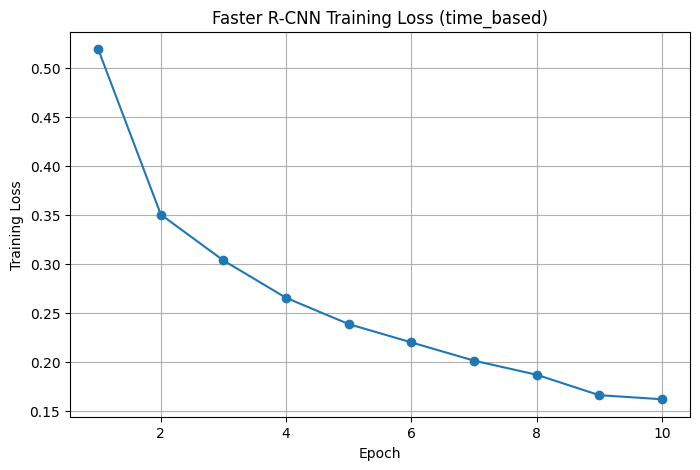

In [ ]:
# ============================================================
# CELL 16 — TRAIN FASTER R-CNN
# ============================================================
def train_one_epoch_frcnn(model, optimizer, data_loader, device, epoch):
    model.train()
    total_loss, total_batches, skipped = 0.0, 0, 0
    start_time = time.time()

    for batch_idx, (images, targets) in enumerate(data_loader):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        if not torch.isfinite(losses):
            skipped += 1
            optimizer.zero_grad()
            continue

        optimizer.zero_grad()
        losses.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        total_loss += losses.item()
        total_batches += 1

        if (batch_idx + 1) % 50 == 0:
            print(f"Epoch [{epoch}] Batch [{batch_idx+1}/{len(data_loader)}] Loss: {losses.item():.4f}")

    avg_loss = total_loss / max(1, total_batches)
    elapsed = time.time() - start_time
    print(f"Epoch [{epoch}] Avg Loss: {avg_loss:.4f} | Skipped: {skipped} | Time: {elapsed:.1f}s")
    return avg_loss, skipped


# === Konfigurasi training ===
NUM_EPOCHS_FRCNN = 10
BENCHMARK_TAG = "time_based" if "time_based" in str(DATASET_ROOT) else "source_based"

FRCNN_RUN_DIR = RUNS_DIR / f"fasterrcnn_resnet50_fpn_{BENCHMARK_TAG}"
FRCNN_RUN_DIR.mkdir(parents=True, exist_ok=True)
FRCNN_BEST_PATH = FRCNN_RUN_DIR / "best_fasterrcnn.pth"

frcnn_model = get_faster_rcnn_model(NUM_CLASSES_FRCNN).to(DEVICE_TORCH)

params = [p for p in frcnn_model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.0005, momentum=0.9, weight_decay=0.0005)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=8, gamma=0.1)

print("Epochs:", NUM_EPOCHS_FRCNN)
print("LR:", optimizer.param_groups[0]["lr"])
print("Save dir:", FRCNN_RUN_DIR)

# === Training loop ===
best_loss = float("inf")
training_history = []

for epoch in range(1, NUM_EPOCHS_FRCNN + 1):
    avg_loss, skipped = train_one_epoch_frcnn(frcnn_model, optimizer, train_loader_frcnn, DEVICE_TORCH, epoch)
    lr_scheduler.step()

    training_history.append({"epoch": epoch, "train_loss": avg_loss, "skipped": skipped})

    if np.isfinite(avg_loss) and avg_loss < best_loss:
        best_loss = avg_loss
        torch.save(frcnn_model.state_dict(), FRCNN_BEST_PATH)
        print(f"✅ Saved best model: {FRCNN_BEST_PATH}")

history_df = pd.DataFrame(training_history)
history_df.to_csv(FRCNN_RUN_DIR / "training_history.csv", index=False)

print("\nTraining done.")
print("Best loss:", best_loss)

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o")
plt.xlabel("Epoch"); plt.ylabel("Training Loss")
plt.title(f"Faster R-CNN Training Loss ({BENCHMARK_TAG})")
plt.grid(True); plt.show()

In [ ]:
# ============================================================
# CELL 17 — EVALUATE FASTER R-CNN (COCO EVAL)
# ============================================================
def frcnn_predict_to_coco_results(model, data_loader, device, score_threshold=0.001):
    model.eval()
    results = []
    with torch.no_grad():
        for images, targets in data_loader:
            images = [img.to(device) for img in images]
            outputs = model(images)
            for target, output in zip(targets, outputs):
                image_id = int(target["image_id"].item())
                boxes  = output["boxes"].detach().cpu().numpy()
                scores = output["scores"].detach().cpu().numpy()
                labels = output["labels"].detach().cpu().numpy()
                for box, score, label in zip(boxes, scores, labels):
                    if score < score_threshold:
                        continue
                    x1, y1, x2, y2 = box.tolist()
                    w, h = x2 - x1, y2 - y1
                    if w <= 0 or h <= 0:
                        continue
                    results.append({
                        "image_id": image_id,
                        "category_id": int(label),
                        "bbox": [float(x1), float(y1), float(w), float(h)],
                        "score": float(score),
                    })
    return results


def build_merged_clamped_coco_gt(split_dir, class_names, keep_classes,
                                  min_box_size=MIN_BOX_SIZE, min_box_area=MIN_BOX_AREA):
    """Build GT COCO JSON yang konsisten dengan filter YOLO."""
    split_dir = Path(split_dir)
    with open(split_dir / "annotations.json", "r", encoding="utf-8") as f:
        coco = json.load(f)

    image_id_to_info = {img["id"]: img for img in coco["images"]}
    original_cat_id_to_name = {cat["id"]: cat["name"] for cat in coco["categories"]}
    class_name_to_label = {name: idx + 1 for idx, name in enumerate(class_names)}
    categories = [
        {"id": idx + 1, "name": name, "supercategory": "object"}
        for idx, name in enumerate(class_names)
    ]

    annotations, ann_id = [], 1
    for ann in coco["annotations"]:
        img_info = image_id_to_info[ann["image_id"]]
        W, H = img_info["width"], img_info["height"]
        x, y, w, h = ann["bbox"]
        if w <= 0 or h <= 0:
            continue
        original_name = original_cat_id_to_name[ann["category_id"]]
        if original_name not in keep_classes:
            continue

        x1 = max(0.0, float(x)); y1 = max(0.0, float(y))
        x2 = min(float(W), float(x + w)); y2 = min(float(H), float(y + h))
        bw, bh = x2 - x1, y2 - y1

        if bw < min_box_size or bh < min_box_size or (bw * bh) < min_box_area:
            continue

        new_ann = ann.copy()
        new_ann["id"] = ann_id
        new_ann["category_id"] = class_name_to_label[original_name]
        new_ann["bbox"] = [x1, y1, bw, bh]
        new_ann["area"] = bw * bh
        new_ann["iscrowd"] = int(ann.get("iscrowd", 0))
        annotations.append(new_ann)
        ann_id += 1

    return {"images": coco["images"], "annotations": annotations, "categories": categories}


# === Load best model ===
frcnn_eval_model = get_faster_rcnn_model(NUM_CLASSES_FRCNN)
frcnn_eval_model.load_state_dict(torch.load(FRCNN_BEST_PATH, map_location=DEVICE_TORCH))
frcnn_eval_model.to(DEVICE_TORCH).eval()
print("Loaded:", FRCNN_BEST_PATH)

# === Predict di test set ===
pred_results = frcnn_predict_to_coco_results(frcnn_eval_model, test_loader_frcnn, DEVICE_TORCH)
print(f"Total predictions: {len(pred_results)}")

# === Build GT (dengan filter yang sama) ===
gt = build_merged_clamped_coco_gt(TEST_DIR, CLASS_NAMES, KEEP_CLASSES)
print(f"GT annotations (filtered): {len(gt['annotations'])}")

# === Save GT & predictions ===
EVAL_DIR_FRCNN = RUNS_EVAL_DIR / f"fasterrcnn_resnet50_fpn_{BENCHMARK_TAG}_test"
EVAL_DIR_FRCNN.mkdir(parents=True, exist_ok=True)

gt_path   = EVAL_DIR_FRCNN / "test_gt_merged_clamped.json"
pred_path = EVAL_DIR_FRCNN / "test_predictions.json"
with open(gt_path, "w", encoding="utf-8") as f:
    json.dump(gt, f)
with open(pred_path, "w", encoding="utf-8") as f:
    json.dump(pred_results, f)

# === COCO Evaluation ===
if len(pred_results) == 0:
    raise RuntimeError("Tidak ada prediksi Faster R-CNN. Evaluasi gagal.")

coco_gt = COCO(str(gt_path))
coco_dt = coco_gt.loadRes(str(pred_path))
coco_eval = COCOeval(coco_gt, coco_dt, "bbox")
coco_eval.evaluate()
coco_eval.accumulate()
coco_eval.summarize()

# === Per-class AP ===
frcnn_per_class_ap = {}
for i, class_name in enumerate(CLASS_NAMES):
    precisions = coco_eval.eval["precision"][:, :, i, 0, -1]
    precisions = precisions[precisions > -1]
    ap = np.mean(precisions) if precisions.size else 0.0
    frcnn_per_class_ap[class_name] = float(ap)
    print(f"  AP {class_name}: {ap:.4f}")

# === Append ke master log ===
eval_name = f"fasterrcnn_{BENCHMARK_TAG}_test"
result = {
    "timestamp": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S"),
    "eval_name": eval_name,
    "model": "fasterrcnn",
    "model_path": str(FRCNN_BEST_PATH),
    "data_yaml": "COCO annotations.json",
    "split": "test",
    "benchmark_group": BENCHMARK_TAG,
    "mAP50": float(coco_eval.stats[1]),
    "mAP75": float(coco_eval.stats[2]),
    "mAP50_95": float(coco_eval.stats[0]),
    **{f"mAP50_95_{k}": v for k, v in frcnn_per_class_ap.items()},
}
append_to_master_log(result)

print(f"\n✅ Saved: {eval_name}")
print(f"  mAP50   : {result['mAP50']:.4f}")
print(f"  mAP75   : {result['mAP75']:.4f}")
print(f"  mAP50-95: {result['mAP50_95']:.4f}")

In [ ]:
# ============================================================
# CELL 18 — VISUAL PREDICTIONS FASTER R-CNN
# ============================================================

from PIL import ImageDraw

def draw_frcnn_predictions(model, images_dir, output_dir, class_names_frcnn,
                            conf=0.50, max_images=None, device="cpu"):
    model.eval()
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    saved_paths = []

    image_files = []
    for ext in ["*.jpg", "*.jpeg", "*.png"]:
        image_files.extend(Path(images_dir).glob(ext))
    if max_images:
        image_files = image_files[:max_images]

    for img_path in image_files:
        image_pil = Image.open(img_path).convert("RGB")
        image_tensor = F_tv.to_tensor(image_pil).unsqueeze(0).to(device)

        with torch.no_grad():
            outputs = model(image_tensor)

        draw = ImageDraw.Draw(image_pil)
        for box, score, label in zip(outputs[0]["boxes"], outputs[0]["scores"], outputs[0]["labels"]):
            if score < conf:
                continue
            x1, y1, x2, y2 = box.tolist()
            class_name = class_names_frcnn[int(label)]
            text = f"{class_name} {score:.2f}"
            draw.rectangle([x1, y1, x2, y2], outline="red", width=3)
            draw.text((x1, max(0, y1 - 12)), text, fill="red")

        save_path = output_dir / img_path.name
        image_pil.save(save_path)
        saved_paths.append(save_path)

    print(f"Prediction dir: {output_dir}")
    print(f"Saved images: {len(saved_paths)}")
    return saved_paths


frcnn_pred_dir = PREDICTIONS_DIR / f"fasterrcnn_{BENCHMARK_TAG}_test_predictions_conf050"
frcnn_saved_preds = draw_frcnn_predictions(
    model=frcnn_eval_model,
    images_dir=TEST_DIR / "images",
    output_dir=frcnn_pred_dir,
    class_names_frcnn=CLASS_NAMES_FRCNN,
    conf=0.50,
    max_images=None,
    device=DEVICE_TORCH,
)

# Tampilkan beberapa sampel
sample_n = 5
if frcnn_saved_preds:
    for img_path in random.sample(frcnn_saved_preds, min(sample_n, len(frcnn_saved_preds))):
        img = Image.open(img_path)
        plt.figure(figsize=(8, 6))
        plt.imshow(img); plt.axis("off"); plt.title(img_path.name)
        plt.show()

In [ ]:
# ============================================================
# CELL 20 — SUMMARY TABLE (UPDATED)
# ============================================================
if MASTER_LOG.exists():
    df = pd.read_csv(MASTER_LOG)
    df_group = df[df["benchmark_group"] == BENCHMARK_TAG].copy()

    summary_cols = ["model", "eval_name", "split", "benchmark_group",
                    "mAP50", "mAP75", "mAP50_95",
                    "mAP50_95_coral", "mAP50_95_fish"]
    available = [c for c in summary_cols if c in df_group.columns]
    summary = df_group[available].sort_values("mAP50_95", ascending=False)

    summary_csv = EXPERIMENT_DIR / f"{BENCHMARK_TAG}_benchmark_summary.csv"
    summary.to_csv(summary_csv, index=False)
    display(summary)
    print("Saved:", summary_csv)
else:
    print("⚠️ Master log belum ada.")

In [28]:
# ============================================================
# REBUILD TIME-BASED MASTER LOG FROM COMPLETED RESULTS
# YOLO11n, YOLO11m, RT-DETR-L ONLY
# ============================================================
import pandas as pd
from pathlib import Path

PROTOCOL = "time_based"
CLEAN_RUN_TAG = "fullset_dedup_v1"

EXPERIMENT_DIR = (
    Path("/content/drive/MyDrive/au-fish/dataset_v2")
    / PROTOCOL
    / "experiment_logs"
)
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

MASTER_LOG = (
    EXPERIMENT_DIR
    / f"all_evaluation_results_{CLEAN_RUN_TAG}.csv"
)

time_results = [
    {
        "model": "yolo11n",
        "eval_name": "yolo11n_time_based_test",
        "split": "test",
        "benchmark_group": "time_based",
        "mAP50": 0.7013,
        "mAP75": 0.4305,
        "mAP50_95": 0.4274,
        "mAP50_95_coral": 0.5390,
        "mAP50_95_fish": 0.3160,
        "images": 282,
        "instances": 1400,
        "background_images": 10,
        "corrupt_images": 0,
    },
    {
        "model": "yolo11m",
        "eval_name": "yolo11m_time_based_test",
        "split": "test",
        "benchmark_group": "time_based",
        "mAP50": 0.7311,
        "mAP75": 0.4810,
        "mAP50_95": 0.4615,
        "mAP50_95_coral": 0.5290,
        "mAP50_95_fish": 0.3940,
        "images": 282,
        "instances": 1400,
        "background_images": 10,
        "corrupt_images": 0,
    },
    {
        "model": "rtdetr_l",
        "eval_name": "rtdetr_l_time_based_test",
        "split": "test",
        "benchmark_group": "time_based",
        "mAP50": 0.7399,
        "mAP75": 0.4995,
        "mAP50_95": 0.4852,
        "mAP50_95_coral": 0.5550,
        "mAP50_95_fish": 0.4160,
        "images": 282,
        "instances": 1400,
        "background_images": 10,
        "corrupt_images": 0,
    },
]

results_df = pd.DataFrame(time_results)

# Menyimpan clean master log time-based.
results_df.to_csv(
    MASTER_LOG,
    index=False,
)

print("✅ Time-based master log created:")
print(MASTER_LOG)

display(
    results_df
    .sort_values(
        "mAP50_95",
        ascending=False,
    )
    .reset_index(drop=True)
)

✅ Time-based master log created:
/content/drive/MyDrive/au-fish/dataset_v2/time_based/experiment_logs/all_evaluation_results_fullset_dedup_v1.csv


,model,eval_name,split,benchmark_group,mAP50,mAP75,mAP50_95,mAP50_95_coral,mAP50_95_fish,images,instances,background_images,corrupt_images
0,rtdetr_l,rtdetr_l_time_based_test,test,time_based,0.7399,0.4995,0.4852,0.555,0.416,282,1400,10,0
1,yolo11m,yolo11m_time_based_test,test,time_based,0.7311,0.4810,0.4615,0.529,0.394,282,1400,10,0
2,yolo11n,yolo11n_time_based_test,test,time_based,0.7013,0.4305,0.4274,0.539,0.316,282,1400,10,0


In [29]:
# ============================================================
# CELL 20 — TIME-BASED SUMMARY TABLE
# NO FASTER R-CNN
# ============================================================
if MASTER_LOG.exists():
    df = pd.read_csv(MASTER_LOG)

    allowed_models = {
        "yolo11n",
        "yolo11m",
        "rtdetr_l",
    }

    df_group = df[
        (df["benchmark_group"] == "time_based")
        & (df["split"] == "test")
        & (df["model"].isin(allowed_models))
    ].copy()

    if df_group.empty:
        print("⚠️ Tidak ada hasil time-based yang sesuai.")

    else:
        summary_cols = [
            "model",
            "eval_name",
            "split",
            "benchmark_group",
            "mAP50",
            "mAP75",
            "mAP50_95",
            "mAP50_95_coral",
            "mAP50_95_fish",
        ]

        available = [
            column
            for column in summary_cols
            if column in df_group.columns
        ]

        summary = (
            df_group[available]
            .drop_duplicates(
                subset=[
                    "model",
                    "split",
                    "benchmark_group",
                ],
                keep="last",
            )
            .sort_values(
                "mAP50_95",
                ascending=False,
            )
            .reset_index(drop=True)
        )

        summary_csv = (
            EXPERIMENT_DIR
            / "time_based_benchmark_summary.csv"
        )

        summary.to_csv(
            summary_csv,
            index=False,
        )

        display(summary)

        print("✅ Summary saved:")
        print(summary_csv)

else:
    print("⚠️ Master log belum ada:", MASTER_LOG)

,model,eval_name,split,benchmark_group,mAP50,mAP75,mAP50_95,mAP50_95_coral,mAP50_95_fish
0,rtdetr_l,rtdetr_l_time_based_test,test,time_based,0.7399,0.4995,0.4852,0.555,0.416
1,yolo11m,yolo11m_time_based_test,test,time_based,0.7311,0.4810,0.4615,0.529,0.394
2,yolo11n,yolo11n_time_based_test,test,time_based,0.7013,0.4305,0.4274,0.539,0.316


✅ Summary saved:
/content/drive/MyDrive/au-fish/dataset_v2/time_based/experiment_logs/time_based_benchmark_summary.csv
